# Exploración y armonización — World Happiness 2015–2019
Objetivo: identificar diferencias de esquema y justificar una fuente integrada para entrenamiento y simulación de streaming. Cada fila representa un país en un año.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import FEATURES
from src.data import load_data, ALIASES
sns.set_theme(style='whitegrid', palette='viridis')


Matplotlib is building the font cache; this may take a moment.


In [2]:
raw = {year: pd.read_csv(ROOT / 'data/raw' / f'{year}.csv') for year in range(2015,2020)}
summary = pd.DataFrame([{'year':y,'rows':len(d),'columns':len(d.columns),'nulls':int(d.isna().sum().sum()),'duplicates':int(d.duplicated().sum())} for y,d in raw.items()])
display(summary)
for year, frame in raw.items():
    print(year)
    display(pd.DataFrame({'dtype':frame.dtypes.astype(str),'missing':frame.isna().sum()}))

,year,rows,columns,nulls,duplicates
0,2015,158,12,0,0
1,2016,157,13,0,0
2,2017,155,12,0,0
3,2018,156,9,1,0
4,2019,156,9,0,0


2015


,dtype,missing
Country,str,0
Region,str,0
Happiness Rank,int64,0
Happiness Score,float64,0
Standard Error,float64,0
Economy (GDP per Capita),float64,0
Family,float64,0
Health (Life Expectancy),float64,0
Freedom,float64,0
Trust (Government Corruption),float64,0


2016


,dtype,missing
Country,str,0
Region,str,0
Happiness Rank,int64,0
Happiness Score,float64,0
Lower Confidence Interval,float64,0
Upper Confidence Interval,float64,0
Economy (GDP per Capita),float64,0
Family,float64,0
Health (Life Expectancy),float64,0
Freedom,float64,0


2017


,dtype,missing
Country,str,0
Happiness.Rank,int64,0
Happiness.Score,float64,0
Whisker.high,float64,0
Whisker.low,float64,0
Economy..GDP.per.Capita.,float64,0
Family,float64,0
Health..Life.Expectancy.,float64,0
Freedom,float64,0
Generosity,float64,0


2018


,dtype,missing
Overall rank,int64,0
Country or region,str,0
Score,float64,0
GDP per capita,float64,0
Social support,float64,0
Healthy life expectancy,float64,0
Freedom to make life choices,float64,0
Generosity,float64,0
Perceptions of corruption,float64,1


2019


,dtype,missing
Overall rank,int64,0
Country or region,str,0
Score,float64,0
GDP per capita,float64,0
Social support,float64,0
Healthy life expectancy,float64,0
Freedom to make life choices,float64,0
Generosity,float64,0
Perceptions of corruption,float64,0


## Esquema unificado
`country` (texto), `year` (entero), seis características numéricas y `happiness_score` (objetivo numérico). `family` agrupa Family/Social support. Son contribuciones del reporte, no cantidades monetarias ni años de vida medidos directamente. La comparabilidad entre ediciones es una limitación de la fuente.

In [3]:
display(pd.DataFrame([{'unified':k,'source_names':' | '.join(v)} for k,v in ALIASES.items()]))
data = load_data()
display(data.head())
display(data.describe(include='all').T)
print('Duplicados país/año:',data.duplicated(['country','year']).sum())
display(data[data.isna().any(axis=1)])

,unified,source_names
0,country,Country | Country or region
1,happiness_score,Happiness Score | Happiness.Score | Score
2,gdp,Economy (GDP per Capita) | Economy..GDP.per.Ca...
3,family,Family | Social support
4,health,Health (Life Expectancy) | Health..Life.Expect...
5,freedom,Freedom | Freedom to make life choices
6,generosity,Generosity
7,corruption,Trust (Government Corruption) | Trust..Governm...


,country,year,gdp,family,health,freedom,generosity,corruption,happiness_score
0,Switzerland,2015,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,7.587
1,Iceland,2015,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,7.561
2,Denmark,2015,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,7.527
3,Norway,2015,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,7.522
4,Canada,2015,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,7.427


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country,782,168,Switzerland,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,782.0,NaN,NaN,NaN,2016.993606,1.417364,2015.0,2016.0,2017.0,2018.0,2019.0
gdp,782.0,NaN,NaN,NaN,0.916047,0.40734,0.0,0.6065,0.982205,1.236187,2.096
family,782.0,NaN,NaN,NaN,1.078392,0.329548,0.0,0.869363,1.124735,1.32725,1.644
health,782.0,NaN,NaN,NaN,0.612416,0.248309,0.0,0.440183,0.64731,0.808,1.141
freedom,782.0,NaN,NaN,NaN,0.411091,0.15288,0.0,0.309768,0.431,0.531,0.724
generosity,782.0,NaN,NaN,NaN,0.218576,0.122321,0.0,0.13,0.201982,0.278832,0.838075
corruption,781.0,NaN,NaN,NaN,0.125436,0.105816,0.0,0.054,0.091,0.15603,0.55191
happiness_score,782.0,NaN,NaN,NaN,5.379018,1.127456,2.693,4.50975,5.322,6.1895,7.769


Duplicados país/año: 0


,country,year,gdp,family,health,freedom,generosity,corruption,happiness_score
489,United Arab Emirates,2018,2.096,0.776,0.67,0.284,0.186,NaN,6.774


## Decisiones de calidad
- Se preservan 782 observaciones y se normalizan espacios y dos variantes explícitas de Taiwan/Hong Kong.
- El único faltante de corrupción se mantiene en la fuente armonizada. En entrenamiento se imputa con la mediana aprendida exclusivamente en el conjunto de entrenamiento. En streaming, el contrato exige números: se guarda el evento original y se rechaza la predicción de ese registro.
- No se imputan el país, año ni objetivo.
- Se excluyen rangos, intervalos, errores estándar y Dystopia Residual: son variables derivadas del objetivo o no están en todos los años. Region tampoco está disponible en todos los archivos.
- No se eliminan automáticamente los extremos: pueden representar diferencias reales entre países.

,potential_outliers
gdp,0
family,10
health,0
freedom,0
generosity,17
corruption,67
happiness_score,0


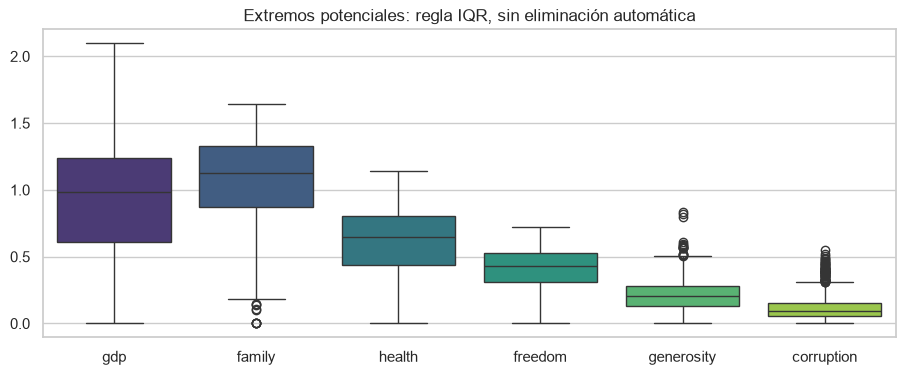

In [4]:
numeric = FEATURES + ['happiness_score']
q1, q3 = data[numeric].quantile(.25), data[numeric].quantile(.75)
iqr = q3-q1
flags = (data[numeric] < q1-1.5*iqr) | (data[numeric] > q3+1.5*iqr)
display(flags.sum().rename('potential_outliers').to_frame())
fig, ax = plt.subplots(figsize=(11,4))
sns.boxplot(data=data[FEATURES],ax=ax)
ax.set_title('Extremos potenciales: regla IQR, sin eliminación automática')
plt.show()

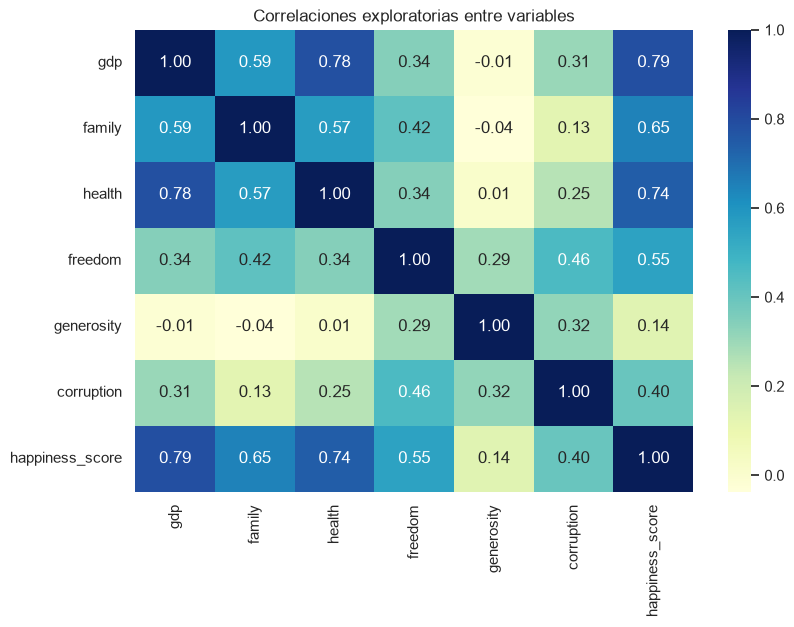

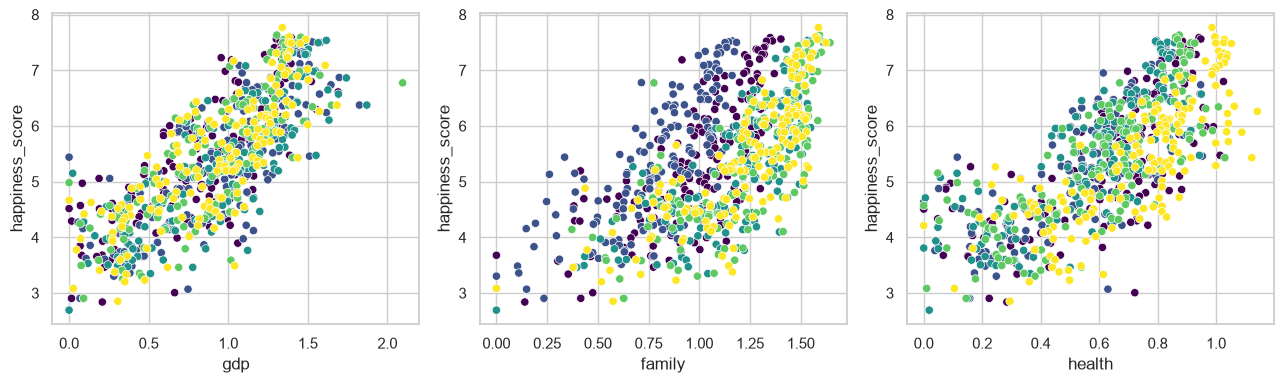

In [5]:
fig, ax = plt.subplots(figsize=(9,6))
sns.heatmap(data[numeric].corr(),annot=True,fmt='.2f',cmap='YlGnBu',ax=ax)
ax.set_title('Correlaciones exploratorias entre variables')
plt.show()
fig, axes = plt.subplots(1,3,figsize=(13,4))
for feature, ax in zip(['gdp','family','health'],axes):
    sns.scatterplot(data=data,x=feature,y='happiness_score',hue='year',palette='viridis',ax=ax,legend=False)
plt.tight_layout()
plt.show()

Las correlaciones son descriptivas, no causales. Se utilizan las seis características comunes por su disponibilidad en el contrato y relación conceptual con el bienestar; no se seleccionan hiperparámetros usando 2019. Los valores atípicos permanecen porque no se verificó que sean errores.

In [6]:
from src.data import prepare
prepared = prepare()
assert len(prepared)==782
assert not prepared.duplicated(['country','year']).any()
print('Fuente armonizada guardada:',prepared.shape)

Fuente armonizada guardada: (782, 9)
